<a href="https://colab.research.google.com/github/snur25/RF-Signal-Classification-DL/blob/main/RF_Classification_Step1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import kagglehub
path = kagglehub.dataset_download("nolasthitnotomorrow/radioml2016-deepsigcom")

Using Colab cache for faster access to the 'radioml2016-deepsigcom' dataset.



Modulation Types (11): ['8PSK', 'AM-DSB', 'AM-SSB', 'BPSK', 'CPFSK', 'GFSK', 'PAM4', 'QAM16', 'QAM64', 'QPSK', 'WBFM']
SNR Levels (20): [-20, -18, -16, -14, -12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12, 14, 16, 18]



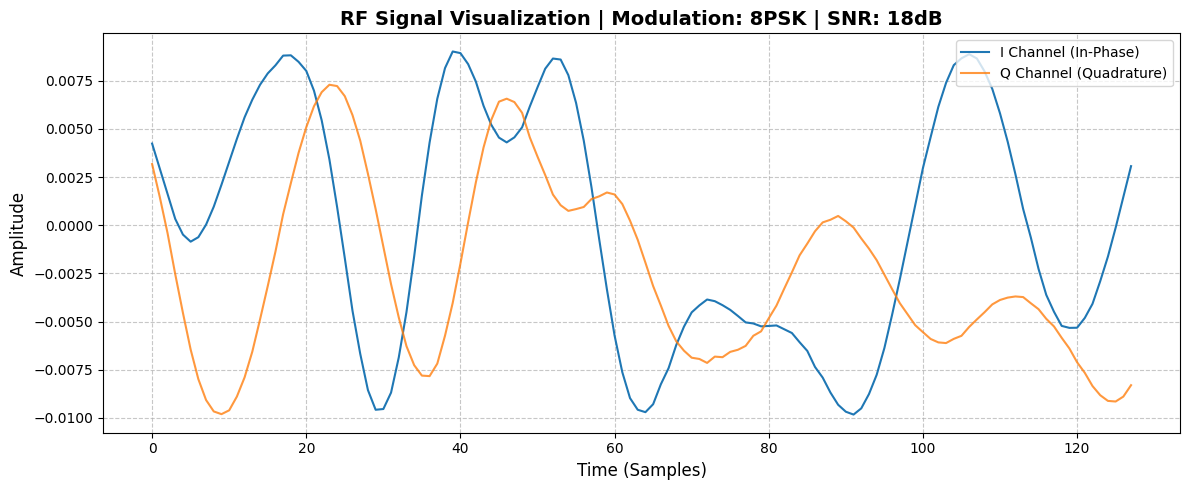

In [5]:
import os
import pickle
import logging
import numpy as np
import matplotlib.pyplot as plt

# Configure standard logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

def load_and_explore_data(dataset_dir: str) -> None:
    """
    Locates the .pkl dataset, loads it into memory, and performs initial EDA.
    Extracts class metadata and visualizes a high-SNR signal sample.
    """
    # 1. Locate the dataset file dynamically
    dataset_path = None
    for root, dirs, files in os.walk(dataset_dir):
        for file in files:
            if file.endswith(".pkl"):
                dataset_path = os.path.join(root, file)
                break

    if not dataset_path:
        logger.error("Dataset .pkl file not found in the specified path.")
        return

    logger.info(f"Loading dataset from: {dataset_path}")

    # 2. Load the dataset (encoding='latin1' is crucial for legacy Python 2 pickles)
    with open(dataset_path, "rb") as f:
        dataset = pickle.load(f, encoding="latin1")

    keys = list(dataset.keys())
    logger.info(f"Dataset successfully loaded. Total Class Combinations: {len(keys)}")

    # 3. Extract metadata (Modulation Types and SNRs)
    modulations = sorted(list(set([k[0] for k in keys])))
    snrs = sorted(list(set([k[1] for k in keys])))

    print("\n" + "="*40)
    print(f"Modulation Types ({len(modulations)}): {modulations}")
    print(f"SNR Levels ({len(snrs)}): {snrs}")
    print("="*40 + "\n")

    # 4. Select a high Signal-to-Noise Ratio (SNR) sample for clear visualization
    target_snr = max(snrs) # Selecting the highest SNR (cleanest signal)
    target_mod = modulations[0]
    sample_key = (target_mod, target_snr)

    # Shape is typically (Num_Samples, Channels, Time_Steps) -> (X, 2, 128)
    sample_signals = dataset[sample_key]
    logger.info(f"Shape of signals for {sample_key}: {sample_signals.shape}")

    # 5. Visualize the first sample
    plot_iq_signal(sample_signals[0], target_mod, target_snr)

def plot_iq_signal(signal: np.ndarray, mod_type: str, snr: int) -> None:
    """
    Plots the In-Phase (I) and Quadrature (Q) components of an RF signal.
    """
    plt.figure(figsize=(12, 5))

    # Channel 0 is I (In-Phase), Channel 1 is Q (Quadrature)
    plt.plot(signal[0, :], label="I Channel (In-Phase)", color="#1f77b4", linewidth=1.5)
    plt.plot(signal[1, :], label="Q Channel (Quadrature)", color="#ff7f0e", linewidth=1.5, alpha=0.8)

    plt.title(f"RF Signal Visualization | Modulation: {mod_type} | SNR: {snr}dB", fontsize=14, fontweight='bold')
    plt.xlabel("Time (Samples)", fontsize=12)
    plt.ylabel("Amplitude", fontsize=12)
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    # Ensure the 'path' variable from kagglehub is passed to the function
    try:
        load_and_explore_data(path)
    except NameError:
        logger.error("The variable 'path' is not defined. Please run the kagglehub cell first.")

In [6]:
import os
import pickle
import logging
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer

# Configure logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger(__name__)

def preprocess_rf_pipeline(dataset_dir: str):
    """
    End-to-end data preprocessing pipeline for RF signals.
    Transforms raw dictionary into Keras-compatible tensors.
    """
    # 1. Locate and load the dataset (using Kagglehub path)
    dataset_path = [os.path.join(dp, f) for dp, dn, filenames in os.walk(dataset_dir) for f in filenames if f.endswith('.pkl')][0]

    with open(dataset_path, "rb") as f:
        dataset = pickle.load(f, encoding="latin1")

    logger.info("Extracting signals and labels from raw dictionary...")

    X, labels, snr_list = [], [], []

    for key in dataset.keys():
        mod_type, snr = key
        signals = dataset[key] # Shape: (N, 2, 128)

        X.append(signals)
        labels.extend([mod_type] * signals.shape[0])
        snr_list.extend([snr] * signals.shape[0])

    # Stack lists into numpy arrays
    X = np.vstack(X)
    labels = np.array(labels)
    snr_list = np.array(snr_list)

    logger.info(f"Original X shape: {X.shape}")

    # 2. Format Conversion: (N, 2, 128) -> (N, 128, 2)
    # Deep Learning models (like 1D CNNs) expect Channel-Last format
    X = np.transpose(X, (0, 2, 1))
    logger.info(f"Transposed X shape for Keras (Channel-Last): {X.shape}")

    # 3. Encode textual labels to categorical (One-Hot Encoding)
    lb = LabelBinarizer()
    y_encoded = lb.fit_transform(labels)
    classes = lb.classes_
    logger.info(f"Classes found ({len(classes)}): {classes}")

    # 4. Train / Validation / Test Split (70% / 15% / 15%)
    # Use stratified split to maintain class balance across sets
    X_temp, X_test, y_temp, y_test, snr_temp, snr_test = train_test_split(
        X, y_encoded, snr_list, test_size=0.15, random_state=42, stratify=y_encoded
    )

    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=0.1765, random_state=42, stratify=y_temp
    ) # 0.1765 of 85% roughly equals 15% of total

    logger.info("Data Split Complete:")
    logger.info(f"Training Set:   X={X_train.shape}, y={y_train.shape}")
    logger.info(f"Validation Set: X={X_val.shape}, y={y_val.shape}")
    logger.info(f"Test Set:       X={X_test.shape}, y={y_test.shape}")

    return X_train, X_val, X_test, y_train, y_val, y_test, snr_test, classes

if __name__ == "__main__":
    # Execute preprocessing and store in global variables for model training
    X_train, X_val, X_test, y_train, y_val, y_test, snr_test, classes = preprocess_rf_pipeline(path)

In [8]:
import sys
import logging
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam

# 1. Environment & Observability Setup
# Explicitly binding logging to sys.stdout ensures Colab UI captures the output
logger = logging.getLogger("BaselineModel")
logger.setLevel(logging.INFO)

# FIX: Prevent messages from bubbling up to the root logger set in Step 2
logger.propagate = False

# Prevent adding multiple handlers if cell is re-run in Colab
if not logger.handlers:
    handler = logging.StreamHandler(sys.stdout)
    formatter = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
    handler.setFormatter(formatter)
    logger.addHandler(handler)

# 2. Baseline Model Architecture
def build_baseline_cnn(input_shape: tuple = (128, 2), num_classes: int = 11) -> Sequential:
    """
    Constructs and compiles the baseline 1D Convolutional Neural Network.

    Args:
        input_shape: Tuple representing (time_steps, channels). Default is (128, 2).
        num_classes: Integer representing the number of modulation targets. Default is 11.

    Returns:
        Compiled tf.keras.Sequential model ready for training.
    """
    logger.info(f"Initializing Baseline 1D-CNN. Input shape: {input_shape}, Classes: {num_classes}")

    model = Sequential([
        Input(shape=input_shape),

        # Feature Extraction Block 1
        Conv1D(filters=64, kernel_size=7, activation='relu', padding='same'),
        MaxPooling1D(pool_size=2),

        # Feature Extraction Block 2
        Conv1D(filters=64, kernel_size=5, activation='relu', padding='same'),
        MaxPooling1D(pool_size=2),

        # Classification Head
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5), # Regularization to prevent overfitting on higher SNRs
        Dense(num_classes, activation='softmax')
    ], name="Baseline_1D_CNN")

    logger.info("Model architecture built successfully. Compiling model...")

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    logger.info("Compilation complete. Model summary:")
    # Route the Keras summary output directly through our stdout logger
    model.summary(print_fn=logger.info)

    return model

if __name__ == "__main__":
    try:
        # These variables are expected to be in memory from Step 2:
        # input_dim = X_train.shape[1:]  # Should evaluate to (128, 2)
        # n_classes = y_train.shape[1]   # Should evaluate to 11

        # Using hardcoded defaults here to test the factory function execution
        baseline_model = build_baseline_cnn(input_shape=(128, 2), num_classes=11)

        logger.info("Baseline model is instantiated and ready for Step 3 training.")
    except Exception as e:
        logger.error(f"Failed to build baseline model: {e}")
        raise

2026-10-10 12:14:15,581 - BaselineModel - INFO - Initializing Baseline 1D-CNN. Input shape: (128, 2), Classes: 11
2026-10-10 12:14:15,624 - BaselineModel - INFO - Model architecture built successfully. Compiling model...
2026-10-10 12:14:15,631 - BaselineModel - INFO - Compilation complete. Model summary:


2026-10-10 12:14:15,646 - BaselineModel - INFO - Model: "Baseline_1D_CNN"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 128, 64)        │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 64, 64)         │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 32, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─

In [10]:
import os
import time
from typing import Dict, Any
import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, History

# Reuse the configured logger from the previous cell
# Assuming `logger` is still in memory; if not, re-fetch it
logger = logging.getLogger("BaselineModel")

def train_baseline(
    model: tf.keras.Model,
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    epochs: int = 50,
    batch_size: int = 512,
    model_dir: str = "./models"
) -> History:
    """
    Executes the training loop for the baseline model with production callbacks.

    Args:
        model: Compiled tf.keras.Model ready for training.
        X_train: Training feature tensor.
        y_train: Training label tensor (One-Hot Encoded).
        X_val: Validation feature tensor.
        y_val: Validation label tensor.
        epochs: Maximum number of training epochs.
        batch_size: Number of samples per gradient update.
        model_dir: Directory path to save the best model artifact.

    Returns:
        History object containing training metrics across epochs.
    """
    logger.info(f"Initiating training loop. Max Epochs: {epochs}, Batch Size: {batch_size}")

    # Ensure artifact directory exists
    os.makedirs(model_dir, exist_ok=True)
    model_path = os.path.join(model_dir, "baseline_1d_cnn_best.keras")

    # 1. Configure Callbacks
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )

    model_checkpoint = ModelCheckpoint(
        filepath=model_path,
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    )

    callbacks = [early_stopping, model_checkpoint]
    logger.info(f"Callbacks configured. Artifacts will be saved to: {model_path}")

    # 2. Execute Training
    start_time = time.time()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=2 # Verbose=2 prints one line per epoch, preventing Colab I/O crash
    )

    elapsed_time = time.time() - start_time
    logger.info(f"Training completed in {elapsed_time:.2f} seconds.")

    # Extract final metrics for the best restored weights
    best_val_loss = min(history.history['val_loss'])
    best_val_acc = max(history.history['val_accuracy'])
    logger.info(f"Best Validation Loss: {best_val_loss:.4f} | Best Validation Accuracy: {best_val_acc:.4f}")

    return history

if __name__ == "__main__":
    try:
        # Assuming baseline_model, X_train, y_train, X_val, y_val are loaded in the Colab kernel
        logger.info("Starting Step 3 model training pipeline...")

        training_history = train_baseline(
            model=baseline_model,
            X_train=X_train,
            y_train=y_train,
            X_val=X_val,
            y_val=y_val
        )

        logger.info("Step 3 Baseline Training is strictly complete.")
    except Exception as e:
        logger.error(f"Training pipeline failed: {e}")
        raise

2026-10-10 12:32:35,310 - BaselineModel - INFO - Starting Step 3 model training pipeline...
2026-10-10 12:32:35,312 - BaselineModel - INFO - Initiating training loop. Max Epochs: 50, Batch Size: 512
2026-10-10 12:32:35,312 - BaselineModel - INFO - Callbacks configured. Artifacts will be saved to: ./models/baseline_1d_cnn_best.keras
Epoch 1/50

Epoch 1: val_loss improved from None to 1.70203, saving model to ./models/baseline_1d_cnn_best.keras

Epoch 1: finished saving model to ./models/baseline_1d_cnn_best.keras
301/301 - 81s - 269ms/step - accuracy: 0.3345 - loss: 1.7616 - val_accuracy: 0.3570 - val_loss: 1.7020
Epoch 2/50

Epoch 2: val_loss improved from 1.70203 to 1.67936, saving model to ./models/baseline_1d_cnn_best.keras

Epoch 2: finished saving model to ./models/baseline_1d_cnn_best.keras
301/301 - 67s - 224ms/step - accuracy: 0.3471 - loss: 1.7297 - val_accuracy: 0.3633 - val_loss: 1.6794
Epoch 3/50

Epoch 3: val_loss improved from 1.67936 to 1.62446, saving model to ./models/